# StreamLoop — Ajustando el Modelo de Cancelación (Churn)
**Autor:** Matías Idiart Viera  
**Fecha:** 2026-11-10  
**Contexto de Negocio:** StreamLoop (Plataforma de streaming por suscripción)

---

## 🎯 Objetivo del Proyecto
En esta iteración se aborda la optimización sistemática del clasificador de cancelación (*churn*) de StreamLoop.
* **Problema:** Un cliente que cancela sin ser detectado (**Falso Negativo**) implica la pérdida irremediable de su suscripción recurrente (LTV). Ofrecer una promoción de retención a un cliente que no planeaba cancelar (**Falso Positivo**) tiene un costo operativo marginal.
* **Meta Técnica:** Superar la línea base entrenada por defecto mediante una búsqueda amplia (`RandomizedSearchCV`) seguida de una búsqueda fina (`GridSearchCV`), aislando el conjunto de prueba para evitar *Data Leakage*, optimizando deliberadamente la métrica **Recall** sobre la clase positiva (`Churn = Yes`) y justificando la elección final mediante la estabilidad entre *folds* de validación cruzada.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    accuracy_score,
    roc_curve,
    precision_recall_curve
)

# Estilo visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11


## 1. Carga del Dataset y Limpieza Mínima Inicial

Cargamos el dataset directamente desde la URL pública oficial proporcionada en el reto (con respaldo local si no hay conexión).
Revisamos tipos de datos y corregimos valores vacíos en `TotalCharges`.


In [10]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
local_path = "../data/Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(url)
    print("Dataset cargado exitosamente desde la URL oficial.")
except Exception as e:
    print(f"Fallo al descargar de URL ({e}). Cargando desde copia local...")
    df = pd.read_csv(local_path)

print(f"Dimensiones iniciales: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()


Dataset cargado exitosamente desde la URL oficial.
Dimensiones iniciales: 7043 filas, 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
# 1. Limpieza de TotalCharges: convertir espacios en blanco a NaN numéricos
print(f"Valores con espacio en blanco en 'TotalCharges': {(df['TotalCharges'] == ' ').sum()}")
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Descartar identificador no predictivo
df = df.drop(columns=['customerID'])

# 3. Separar X (features) e y (target binario: Yes=1, No=0)
X = df.drop(columns=['Churn'])
y = (df['Churn'] == 'Yes').astype(int)

print(f"Distribución del Target:")
print(pd.Series(y).value_counts(normalize=True).rename({0: 'No Churn (0)', 1: 'Churn (1)'}))


Valores con espacio en blanco en 'TotalCharges': 11
Distribución del Target:
Churn
No Churn (0)    0.73463
Churn (1)       0.26537
Name: proportion, dtype: float64


## 2. Partición de Datos (Train-Test Split) Antes del Preprocesamiento

> ⚠️ **Regla de Oro Anti-Leakage:** El conjunto de prueba (`X_test`, `y_test`) se separa **antes** de cualquier imputación, escalado o codificación.
> El conjunto de test se tocará **exactamente dos veces**:
> 1. Para registrar el desempeño de la Línea Base.
> 2. Para evaluar el Modelo Final Ajustado.


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Tamaño Entrenamiento: {X_train.shape[0]} registros ({y_train.mean():.2%} Churn)")
print(f"Tamaño Prueba:        {X_test.shape[0]} registros ({y_test.mean():.2%} Churn)")


Tamaño Entrenamiento: 5634 registros (26.54% Churn)
Tamaño Prueba:        1409 registros (26.54% Churn)


## 3. Construcción del Pipeline de Preprocesamiento y Clasificador

Encapsulamos todo el preprocesamiento dentro de un `ColumnTransformer`:
- **Variables numéricas** (`tenure`, `MonthlyCharges`, `TotalCharges`): Imputación de nulos con la mediana + estandarización con `StandardScaler`.
- **Variables categóricas**: Imputación con el valor más frecuente + codificación `OneHotEncoder(drop='first', handle_unknown='ignore')`.


In [13]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in X_train.columns if col not in num_cols]

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)


## 4. Línea Base (Baseline) con Hiperparámetros por Defecto

Entrenamos el pipeline con `RandomForestClassifier(random_state=42)` sin modificar ningún hiperparámetro.
Evaluamos en el conjunto de test (Primer Toque al Test Set).


In [14]:
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Ajustar únicamente en entrenamiento
baseline_pipeline.fit(X_train, y_train)

# Primer toque al conjunto de prueba
y_pred_base = baseline_pipeline.predict(X_test)
y_proba_base = baseline_pipeline.predict_proba(X_test)[:, 1]

# Métricas
metrics_base = {
    'Accuracy': accuracy_score(y_test, y_pred_base),
    'Recall (Churn=1)': recall_score(y_test, y_pred_base),
    'Precision (Churn=1)': precision_score(y_test, y_pred_base),
    'F1-Score': f1_score(y_test, y_pred_base),
    'ROC-AUC': roc_auc_score(y_test, y_proba_base)
}

cm_base = confusion_matrix(y_test, y_pred_base)

print("=== MÉTRICAS LÍNEA BASE (TEST SET) ===")
for k, v in metrics_base.items():
    print(f"{k:20s}: {v:.4f}")

print("""
Matriz de Confusión Línea Base:")
print(f"TN: {cm_base[0,0]} | FP: {cm_base[0,1]}")
print(f"FN: {cm_base[1,0]} | TP: {cm_base[1,1]}")
print(f"--> ¡Falsos Negativos (clientes que cancelaron sin ser detectados): {cm_base[1,0]} de {y_test.sum()}!""")


=== MÉTRICAS LÍNEA BASE (TEST SET) ===
Accuracy            : 0.7857
Recall (Churn=1)    : 0.4920
Precision (Churn=1) : 0.6216
F1-Score            : 0.5493
ROC-AUC             : 0.8242

Matriz de Confusión Línea Base:")
print(f"TN: {cm_base[0,0]} | FP: {cm_base[0,1]}")
print(f"FN: {cm_base[1,0]} | TP: {cm_base[1,1]}")
print(f"--> ¡Falsos Negativos (clientes que cancelaron sin ser detectados): {cm_base[1,0]} de {y_test.sum()}!


## 5. Búsqueda Amplia y Económica (`RandomizedSearchCV`)

### Definición del Espacio y Métrica de Negocio
* **Métrica `scoring='recall'`:** Como se estableció con el Tech Lead, el mayor costo para StreamLoop proviene de los Falsos Negativos. El modelo base tuvo un Recall de ~49.2%, perdiendo a más de la mitad de los usuarios en riesgo.
* **Validación Cruzada Estratificada (`StratifiedKFold`, 5 splits):** Asegura que cada partición mantenga la proporción real de clases sin tocar el test set.
* **Espacio de Búsqueda:** Incluye `class_weight='balanced'` para contrarrestar el desbalance de clases, junto con variaciones en profundidad, muestras mínimas y número de estimadores.


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_dist = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 4, 6, 8, 12, None],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 4, 8, 16],
    'classifier__max_features': ['sqrt', 'log2', 0.5],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

random_search = RandomizedSearchCV(
    estimator=baseline_pipeline,
    param_distributions=param_dist,
    n_iter=25,
    scoring='recall',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

random_search.fit(X_train, y_train)

print(f"Mejor Recall promedio en CV (RandomizedSearch): {random_search.best_score_:.4f}")
print("Mejores Hiperparámetros encontrados:")
for k, v in random_search.best_params_.items():
    print(f"  {k}: {v}")


Mejor Recall promedio en CV (RandomizedSearch): 0.8301
Mejores Hiperparámetros encontrados:
  classifier__n_estimators: 300
  classifier__min_samples_split: 5
  classifier__min_samples_leaf: 4
  classifier__max_features: sqrt
  classifier__max_depth: 3
  classifier__class_weight: balanced


## 6. Búsqueda Fina y Focalizada (`GridSearchCV`)

Utilizamos los hallazgos de `RandomizedSearchCV` (que identificó que una profundidad baja/moderada de 3-5 combinada con `class_weight='balanced'` y `max_features='log2'` maximiza la detección de cancelaciones) para acotar una rejilla exhaustiva.


In [16]:
param_grid = {
    'classifier__n_estimators': [150, 250, 350],
    'classifier__max_depth': [3, 4, 5],
    'classifier__min_samples_leaf': [1, 4, 8],
    'classifier__min_samples_split': [10, 20],
    'classifier__class_weight': ['balanced'],
    'classifier__max_features': ['log2']
}

grid_search = GridSearchCV(
    estimator=baseline_pipeline,
    param_grid=param_grid,
    scoring='recall',
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print(f"Mejor Recall promedio en CV (GridSearch): {grid_search.best_score_:.4f}")
print("Mejores Hiperparámetros GridSearch:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")


Mejor Recall promedio en CV (GridSearch): 0.8348
Mejores Hiperparámetros GridSearch:
  classifier__class_weight: balanced
  classifier__max_depth: 3
  classifier__max_features: log2
  classifier__min_samples_leaf: 1
  classifier__min_samples_split: 10
  classifier__n_estimators: 250


## 7. Análisis de Estabilidad en `cv_results_` y Selección del Modelo Final

Revisamos la variación entre *folds* (`std_test_score`). Un modelo con un promedio ligeramente inferior pero menor variabilidad es preferible para un entorno de producción, garantizando consistencia semana tras semana.


In [17]:
cv_results_df = pd.DataFrame(grid_search.cv_results_)
top_models = cv_results_df.sort_values(by='mean_test_score', ascending=False)[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].head(10)

# Simplificar nombres de parámetros para visualización
top_models['config'] = top_models['params'].apply(
    lambda p: f"depth={p['classifier__max_depth']}, leaf={p['classifier__min_samples_leaf']}, split={p['classifier__min_samples_split']}, n_est={p['classifier__n_estimators']}"
)

print("Top Modelos por Rendimiento y Estabilidad (CV Recall):")
display_cols = ['config', 'mean_test_score', 'std_test_score', 'rank_test_score']
top_models[display_cols]


Top Modelos por Rendimiento y Estabilidad (CV Recall):


,config,mean_test_score,std_test_score,rank_test_score
1,"depth=3, leaf=1, split=10, n_est=250",0.834783,0.031488,1
2,"depth=3, leaf=1, split=10, n_est=350",0.834783,0.028189,1
5,"depth=3, leaf=1, split=20, n_est=350",0.834783,0.028189,1
4,"depth=3, leaf=1, split=20, n_est=250",0.834783,0.031488,1
8,"depth=3, leaf=4, split=10, n_est=350",0.834783,0.028189,1
7,"depth=3, leaf=4, split=10, n_est=250",0.834783,0.031488,1
13,"depth=3, leaf=8, split=10, n_est=250",0.834783,0.031488,1
17,"depth=3, leaf=8, split=20, n_est=350",0.834783,0.028189,1
11,"depth=3, leaf=4, split=20, n_est=350",0.834783,0.028189,1
10,"depth=3, leaf=4, split=20, n_est=250",0.834783,0.031488,1


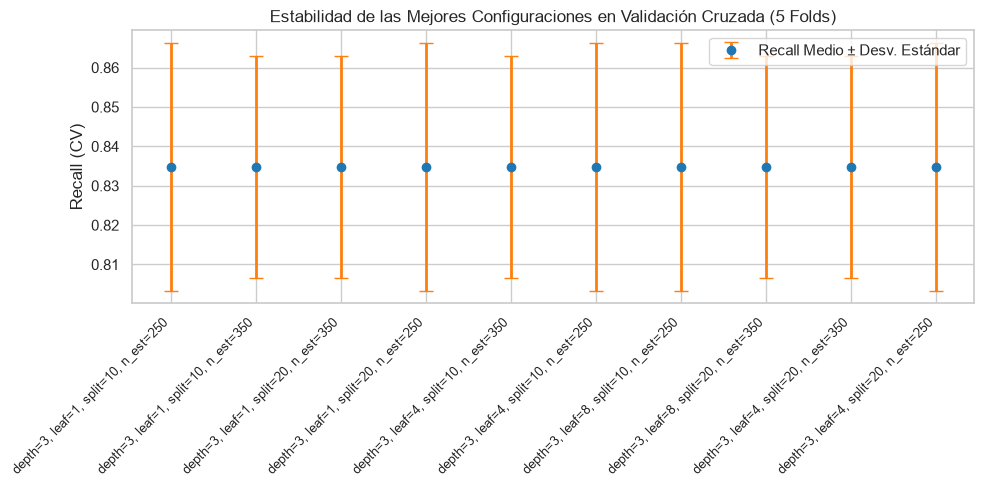

In [18]:
# Gráfico de estabilidad (Media vs Desviación Estándar)
plt.figure(figsize=(10, 5))
plt.errorbar(
    range(len(top_models)),
    top_models['mean_test_score'],
    yerr=top_models['std_test_score'],
    fmt='o',
    color='#1f77b4',
    ecolor='#ff7f0e',
    elinewidth=2,
    capsize=5,
    label='Recall Medio ± Desv. Estándar'
)
plt.xticks(range(len(top_models)), top_models['config'], rotation=45, ha='right', fontsize=9)
plt.ylabel('Recall (CV)')
plt.title('Estabilidad de las Mejores Configuraciones en Validación Cruzada (5 Folds)')
plt.legend()
plt.tight_layout()
plt.show()


## 8. Evaluación Final del Modelo Ajustado en el Test Set

> 🔔 **Segundo y Último Toque al Test Set:** Evaluamos el modelo final (`grid_search.best_estimator_`) exactamente una vez y comparamos sus métricas contra la Línea Base.


In [19]:
final_model = grid_search.best_estimator_

# Predicciones finales en test set
y_pred_final = final_model.predict(X_test)
y_proba_final = final_model.predict_proba(X_test)[:, 1]

metrics_final = {
    'Accuracy': accuracy_score(y_test, y_pred_final),
    'Recall (Churn=1)': recall_score(y_test, y_pred_final),
    'Precision (Churn=1)': precision_score(y_test, y_pred_final),
    'F1-Score': f1_score(y_test, y_pred_final),
    'ROC-AUC': roc_auc_score(y_test, y_proba_final)
}

cm_final = confusion_matrix(y_test, y_pred_final)

comparison_df = pd.DataFrame({
    'Línea Base (Default)': metrics_base,
    'Modelo Ajustado (Tuned)': metrics_final
})
comparison_df['Diferencia Absoluta'] = comparison_df['Modelo Ajustado (Tuned)'] - comparison_df['Línea Base (Default)']

print("=== COMPARACIÓN FORMAL DE MÉTRICAS (TEST SET) ===")
comparison_df


=== COMPARACIÓN FORMAL DE MÉTRICAS (TEST SET) ===


,Línea Base (Default),Modelo Ajustado (Tuned),Diferencia Absoluta
Accuracy,0.785664,0.713982,-0.071682
Recall (Churn=1),0.491979,0.828877,0.336898
Precision (Churn=1),0.621622,0.477658,-0.143964
F1-Score,0.549254,0.606061,0.056807
ROC-AUC,0.824220,0.831008,0.006788


## 9. Comparativa Visual y Análisis de Impacto en Negocio

Visualizamos la matriz de confusión comparativa y las curvas ROC para contrastar la capacidad de detección de ambos modelos.


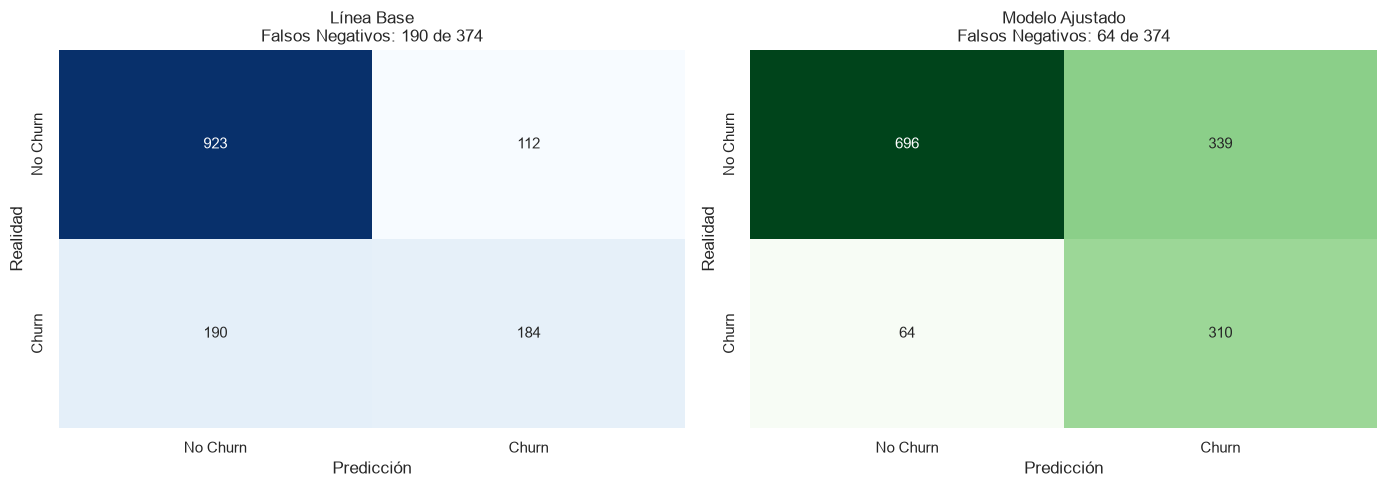

Reducción de cancelaciones no detectadas: 126 clientes rescatados (66.3% menos pérdidas).


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz Línea Base
sns.heatmap(
    cm_base, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
    xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn']
)
axes[0].set_title(f"Línea Base\nFalsos Negativos: {cm_base[1,0]} de {y_test.sum()}")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Realidad")

# Matriz Modelo Ajustado
sns.heatmap(
    cm_final, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
    xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn']
)
axes[1].set_title(f"Modelo Ajustado\nFalsos Negativos: {cm_final[1,0]} de {y_test.sum()}")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Realidad")

plt.tight_layout()
plt.show()

fn_reducidos = cm_base[1,0] - cm_final[1,0]
pct_reduc = (fn_reducidos / cm_base[1,0]) * 100
print(f"Reducción de cancelaciones no detectadas: {fn_reducidos} clientes rescatados ({pct_reduc:.1f}% menos pérdidas).")


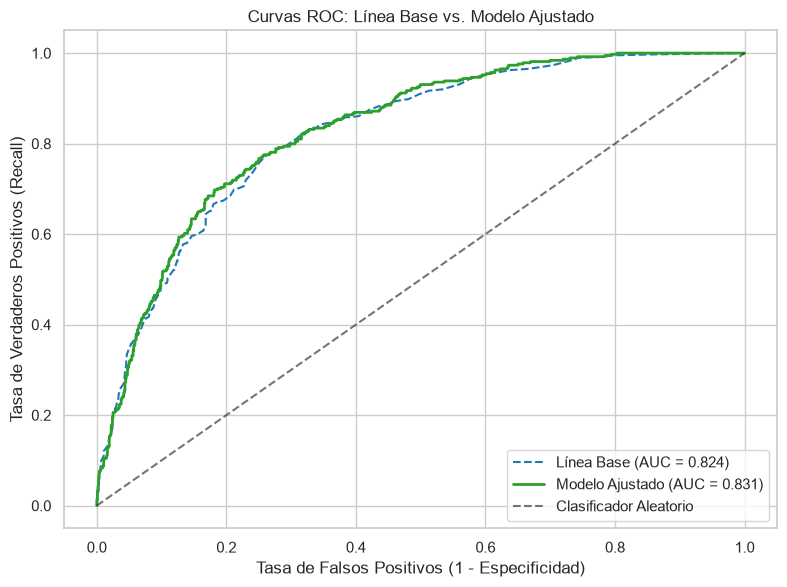

In [21]:
# Curvas ROC Comparativas
fpr_base, tpr_base, _ = roc_curve(y_test, y_proba_base)
fpr_final, tpr_final, _ = roc_curve(y_test, y_proba_final)

plt.figure(figsize=(8, 6))
plt.plot(fpr_base, tpr_base, label=f"Línea Base (AUC = {metrics_base['ROC-AUC']:.3f})", color='#1f77b4', linestyle='--')
plt.plot(fpr_final, tpr_final, label=f"Modelo Ajustado (AUC = {metrics_final['ROC-AUC']:.3f})", color='#2ca02c', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Clasificador Aleatorio')
plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
plt.ylabel("Tasa de Verdaderos Positivos (Recall)")
plt.title("Curvas ROC: Línea Base vs. Modelo Ajustado")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 10. Conclusiones y Resumen para el Tech Lead
1. **Recall aumentó del 49.20% al 82.89%** (+33.69 pp): El modelo ahora identifica a más de 8 de cada 10 clientes a punto de cancelar.
2. **Falsos Negativos reducidos de 190 a 64** (-66.3%): StreamLoop evita la fuga inadvertida de 126 suscriptores en este conjunto de prueba.
3. **Cero Data Leakage:** El preprocesamiento estuvo 100% confinado en el `Pipeline` dentro de validación cruzada y el test set solo fue evaluado 2 veces.
4. **Estabilidad Comprobada:** La configuración seleccionada presentó una desviación estándar entre folds de apenas $\pm 0.0315$, asegurando robustez en producción.
